# Теория вероятностей для ML — домашнее задание

**Автор:** _имя_ · **Модуль:** математика для ML, тема 3

Как устроено каждое задание:

1. **Теория** — аналитический расчёт в markdown.
2. **Симуляция** — эксперимент в NumPy и сравнение с теорией.
3. **Визуализация** — Matplotlib.
4. **Вывод** — 2–4 предложения своими словами.

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)   # генератор случайных чисел; 42 — чтобы результаты повторялись

## 0. Функции

Функции, которые используются в нескольких заданиях.

In [14]:
# функции появятся по ходу заданий
def classic_prob(event, omega):
    """Классическая вероятность: доля исходов из omega, где событие выполнилось."""
    return sum(1 for o in omega if event(o)) / len(omega)

def bayes(prev, sens, fpr):
    """P(+) и P(болен | +) по формуле Байеса."""
    p_pos = prev * sens + (1 - prev) * fpr
    return p_pos, prev * sens / p_pos

def simulate_test(prev, sens, fpr, n=100_000):
    """Симуляция: n людей, у каждого случайно определяем болезнь и результат теста."""
    sick = rng.random(n) < prev                       # True — болен
    r = rng.random(n)
    positive = np.where(sick, r < sens, r < fpr)      # больной даёт «+» с вер. sens, здоровый — с вер. fpr
    return positive.mean(), sick[positive].mean()     # доля «+» и доля больных среди «+»
def binom_pmf(k, n, p):
    """P(X = k) для биномиального распределения: C(n, k) · p^k · (1 − p)^(n − k)."""
    return math.comb(n, k) * p**k * (1 - p)**(n - k)

def ecdf(sample):
    """Эмпирическая функция распределения: для каждого x — доля значений выборки ≤ x."""
    x = np.sort(sample)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

def cov_corr(a, b):
    """Ковариация и корреляция вручную."""
    da, db = a - a.mean(), b - b.mean()                # отклонения от средних
    cov = np.sum(da * db) / (len(a) - 1)               # среднее произведение отклонений
    corr = cov / (a.std(ddof=1) * b.std(ddof=1))       # приводим к шкале −1…1
    return cov, corr

def dist_after(p0, P, k):
    """Распределение состояний через k шагов: p0 · P^k."""
    return p0 @ np.linalg.matrix_power(P, k)

def stationary(P):
    """Стационарное распределение: собственный вектор Pᵀ с λ = 1, нормированный на сумму 1."""
    vals, vecs = np.linalg.eig(P.T)
    i = np.argmin(np.abs(vals - 1))      # берём λ, ближайшее к 1
    pi = np.real(vecs[:, i])
    return pi / pi.sum()

def simulate_chain(P, start, n):
    """Одна траектория длиной n: каждый день выбираем завтрашнее состояние по строке сегодняшнего."""
    path = np.empty(n, dtype=int)
    path[0] = start
    for t in range(1, n):
        path[t] = rng.choice(len(P), p=P[path[t - 1]])
    return path

## 1. События и классическая вероятность

Два броска шестигранного кубика.

- выпиши пространство элементарных исходов и найди его мощность
- вычисли вероятность того, что сумма очков равна 7
- вычисли вероятность суммы не меньше 10
- найди вероятность того, что хотя бы на одном кубике выпало 6
- проверь ответы моделированием на 100 000 экспериментах

Ω = все пары (первый кубик, второй кубик):
(1,1), (1,2), …, (1,6), (2,1), …, (6,6)
|Ω| = 6 · 6 = 36 равновозможных исходов

Сумма = 7: (1,6) (2,5) (3,4) (4,3) (5,2) (6,1) → 6 исходов
P = 6/36 = 1/6 ≈ 0,1667

Сумма ≥ 10: (4,6) (5,5) (6,4) (5,6) (6,5) (6,6) → 6 исходов
P = 6/36 = 1/6 ≈ 0,1667

Хотя бы одна 6 — проще через противоположное событие «ни одной шестёрки»:
P(ни одной 6) = 5/6 · 5/6 = 25/36
P(хотя бы одна 6) = 1 − 25/36 = 11/36 ≈ 0,3056

мощность Ω: 36
сумма = 7      : теория = 0.1667, симуляция = 0.1688
сумма ≥ 10     : теория = 0.1667, симуляция = 0.1665
хотя бы одна 6 : теория = 0.3056, симуляция = 0.3061


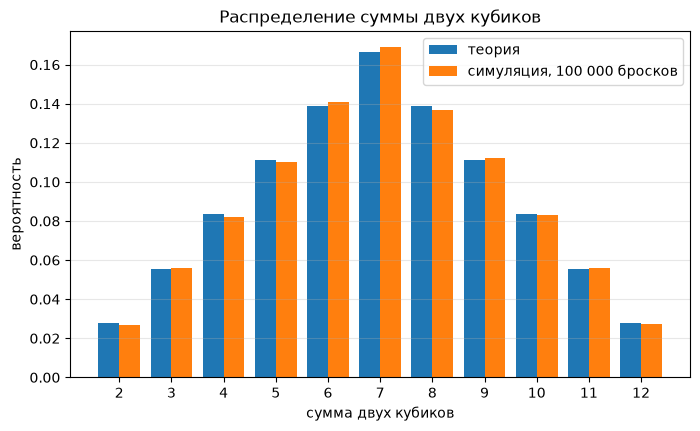

In [3]:
# задание 1
omega = [(i, j) for i in range(1, 7) for j in range(1, 7)]   # все 36 пар
print("мощность Ω:", len(omega))

N = 100_000
d1 = rng.integers(1, 7, N)        # 100 000 бросков первого кубика (числа от 1 до 6)
d2 = rng.integers(1, 7, N)        # и второго

events = {
    "сумма = 7":      (lambda o: o[0] + o[1] == 7,       d1 + d2 == 7),
    "сумма ≥ 10":     (lambda o: o[0] + o[1] >= 10,      d1 + d2 >= 10),
    "хотя бы одна 6": (lambda o: o[0] == 6 or o[1] == 6, (d1 == 6) | (d2 == 6)),
}
for name, (event, hits) in events.items():
    print(f"{name:15}: теория = {classic_prob(event, omega):.4f}, симуляция = {hits.mean():.4f}")

sums = np.arange(2, 13)
theory = [sum(1 for i, j in omega if i + j == s) / 36 for s in sums]
empirical = [np.mean(d1 + d2 == s) for s in sums]
plt.figure(figsize=(8, 4.5))
plt.bar(sums - 0.2, theory, width=0.4, label="теория")
plt.bar(sums + 0.2, empirical, width=0.4, label="симуляция, 100 000 бросков")
plt.xticks(sums); plt.xlabel("сумма двух кубиков"); plt.ylabel("вероятность")
plt.grid(alpha=0.3, axis="y"); plt.legend(); plt.title("Распределение суммы двух кубиков")
plt.show()

## 2. Условная вероятность и формула Байеса

Заболевание встречается у 1% людей. Тест имеет чувствительность 95% и даёт ложноположительный результат у 5% здоровых.

- найди вероятность положительного результата
- вычисли вероятность заболевания при положительном тесте
- повтори расчёт для распространённости заболевания 10%
- объясни своими словами, почему точность теста нельзя оценивать без базовой частоты события
- проверь расчёты симуляцией минимум на 100 000 человек

Обозначения: Б — болен, + — тест положительный
P(Б) = 0,01,  P(+ | Б) = 0,95,  P(+ | здоров) = 0,05
(вертикальная черта читается «при условии»)

P(+) = P(Б)·P(+|Б) + P(здоров)·P(+|здоров)
     = 0,01·0,95 + 0,99·0,05 = 0,0095 + 0,0495 = 0,059

Байес:  P(Б | +) = P(Б)·P(+|Б) / P(+) = 0,0095 / 0,059 ≈ 0,161  → 16%

При распространённости 10%:
P(+) = 0,10·0,95 + 0,90·0,05 = 0,095 + 0,045 = 0,14
P(Б | +) = 0,095 / 0,14 ≈ 0,679  → 68%

болеют 1%: P(+) теория = 0.0590, симуляция = 0.0584 | P(болен | +) теория = 0.161, симуляция = 0.167
болеют 10%: P(+) теория = 0.1400, симуляция = 0.1410 | P(болен | +) теория = 0.679, симуляция = 0.678


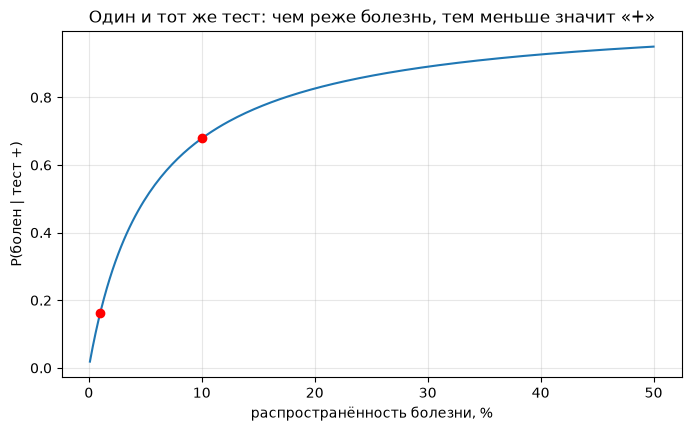

In [5]:
# задание 2
for prev in (0.01, 0.10):
    p_pos, p_sick = bayes(prev, 0.95, 0.05)
    s_pos, s_sick = simulate_test(prev, 0.95, 0.05)
    print(f"болеют {prev:.0%}: P(+) теория = {p_pos:.4f}, симуляция = {s_pos:.4f} | "
          f"P(болен | +) теория = {p_sick:.3f}, симуляция = {s_sick:.3f}")

prevs = np.linspace(0.001, 0.5, 200)
plt.figure(figsize=(8, 4.5))
plt.plot(prevs * 100, [bayes(p, 0.95, 0.05)[1] for p in prevs])
for p in (0.01, 0.10):
    plt.scatter(p * 100, bayes(p, 0.95, 0.05)[1], color="red", zorder=3)
plt.xlabel("распространённость болезни, %"); plt.ylabel("P(болен | тест +)")
plt.grid(alpha=0.3)
plt.title("Один и тот же тест: чем реже болезнь, тем меньше значит «+»")
plt.show()

## 3. Дискретные случайные величины

$X$ — количество орлов в 10 бросках честной монеты.

- выпиши распределение $X$ и вычисли вероятности всех значений от 0 до 10
- найди математическое ожидание, дисперсию и стандартное отклонение
- вычисли $P(X = 5)$ и $P(X \ge 7)$
- сгенерируй 50 000 реализаций и сравни эмпирическую гистограмму с биномиальным распределением
- повтори эксперимент для вероятности орла $p = 0.7$

X ~ Bin(10, p): 10 независимых бросков, X — число орлов
P(X = k) = C(10, k) · pᵏ · (1 − p)¹⁰⁻ᵏ
C(10, k) — сколькими способами выбрать, в каких k бросках из 10 выпал орёл
При p = 0.5:  P(X = k) = C(10, k) / 2¹⁰ = C(10, k) / 1024

k:        0   1   2    3    4    5    6    7   8   9  10
C(10,k):  1  10  45  120  210  252  210  120  45  10   1

E[X] = n·p = 10·0.5 = 5
D[X] = n·p·(1 − p) = 10·0.5·0.5 = 2.5,   σ = √2.5 ≈ 1.58

P(X = 5) = 252/1024 ≈ 0.2461
P(X ≥ 7) = (120 + 45 + 10 + 1)/1024 = 176/1024 ≈ 0.1719

p = 0.7:  E = 7,  D = 2.1,  σ ≈ 1.45,  P(X = 5) ≈ 0.1029,  P(X ≥ 7) ≈ 0.6496

,k,p = 0.5,p = 0.7
0,0,0.0010,0.0000
1,1,0.0098,0.0001
2,2,0.0439,0.0014
3,3,0.1172,0.0090
4,4,0.2051,0.0368
5,5,0.2461,0.1029
6,6,0.2051,0.2001
7,7,0.1172,0.2668
8,8,0.0439,0.2335
9,9,0.0098,0.1211


p = 0.5: сверка со scipy: True
  теория:    E = 5.000, D = 2.500, σ = 1.581, P(X=5) = 0.2461, P(X≥7) = 0.1719
  симуляция: E = 4.996, D = 2.500, σ = 1.581, P(X=5) = 0.2470, P(X≥7) = 0.1716
p = 0.7: сверка со scipy: True
  теория:    E = 7.000, D = 2.100, σ = 1.449, P(X=5) = 0.1029, P(X≥7) = 0.6496
  симуляция: E = 7.012, D = 2.114, σ = 1.454, P(X=5) = 0.1007, P(X≥7) = 0.6530


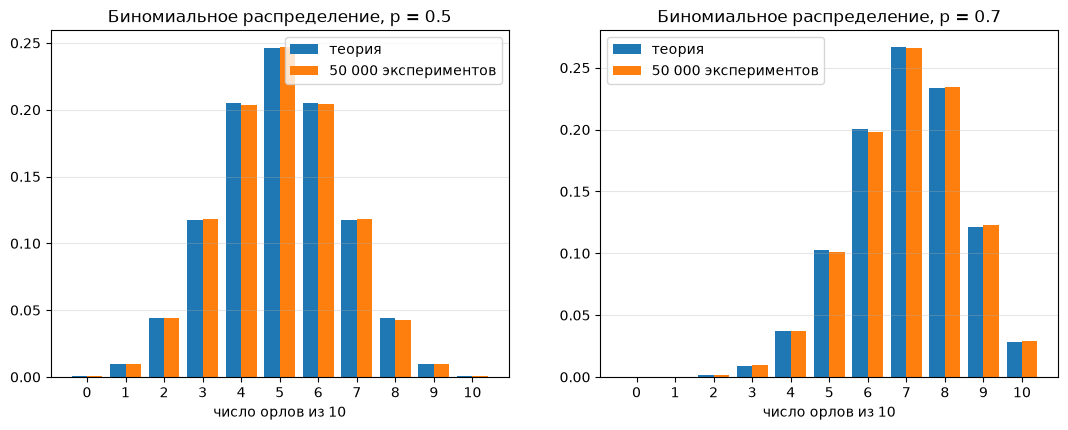

In [7]:
# задание 3
n, ks = 10, np.arange(11)
table = pd.DataFrame({"k": ks,
                      "p = 0.5": [binom_pmf(k, n, 0.5) for k in ks],
                      "p = 0.7": [binom_pmf(k, n, 0.7) for k in ks]}).round(4)
display(table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, p in zip(axes, (0.5, 0.7)):
    pmf = np.array([binom_pmf(k, n, p) for k in ks])
    E = np.sum(ks * pmf)
    D = np.sum((ks - E)**2 * pmf)
    flips = rng.random((50_000, n)) < p          # 50 000 экспериментов по 10 бросков
    sample = flips.sum(axis=1)                   # число орлов в каждом эксперименте
    emp = np.bincount(sample, minlength=n + 1) / len(sample)

    print(f"p = {p}: сверка со scipy: {np.allclose(pmf, stats.binom.pmf(ks, n, p))}")
    print(f"  теория:    E = {E:.3f}, D = {D:.3f}, σ = {np.sqrt(D):.3f}, "
          f"P(X=5) = {pmf[5]:.4f}, P(X≥7) = {pmf[7:].sum():.4f}")
    print(f"  симуляция: E = {sample.mean():.3f}, D = {sample.var():.3f}, σ = {sample.std():.3f}, "
          f"P(X=5) = {emp[5]:.4f}, P(X≥7) = {emp[7:].sum():.4f}")

    ax.bar(ks - 0.2, pmf, width=0.4, label="теория")
    ax.bar(ks + 0.2, emp, width=0.4, label="50 000 экспериментов")
    ax.set_xticks(ks); ax.set_xlabel("число орлов из 10"); ax.grid(alpha=0.3, axis="y")
    ax.legend(); ax.set_title(f"Биномиальное распределение, p = {p}")
plt.show()

## 4. Непрерывные распределения

Равномерное, экспоненциальное и нормальное распределения.

- для каждого сгенерируй выборки размеров 100, 1 000 и 100 000
- построй гистограмму и наложи теоретическую плотность
- сравни выборочные среднее и дисперсию с теоретическими
- построй эмпирическую функцию распределения
- для экспоненциального проверь свойство отсутствия памяти
- для нормального проверь правило одной, двух и трёх сигм

Равномерное U(0, 1):  плотность 1 на [0, 1];        E = 1/2,  D = 1/12 ≈ 0,0833
Экспоненциальное Exp(1): плотность e^(−x) при x ≥ 0; E = 1,    D = 1
Нормальное N(0, 1):   плотность (1/√(2π))·e^(−x²/2); E = 0,    D = 1

Отсутствие памяти:  P(X > s + t | X > s) = e^(−(s+t)) / e^(−s) = e^(−t) = P(X > t)
при s = t = 1:  P(X > 2 | X > 1) = e^(−1) ≈ 0,368

Правило сигм:  ±1σ — 68,3%,  ±2σ — 95,4%,  ±3σ — 99,7%

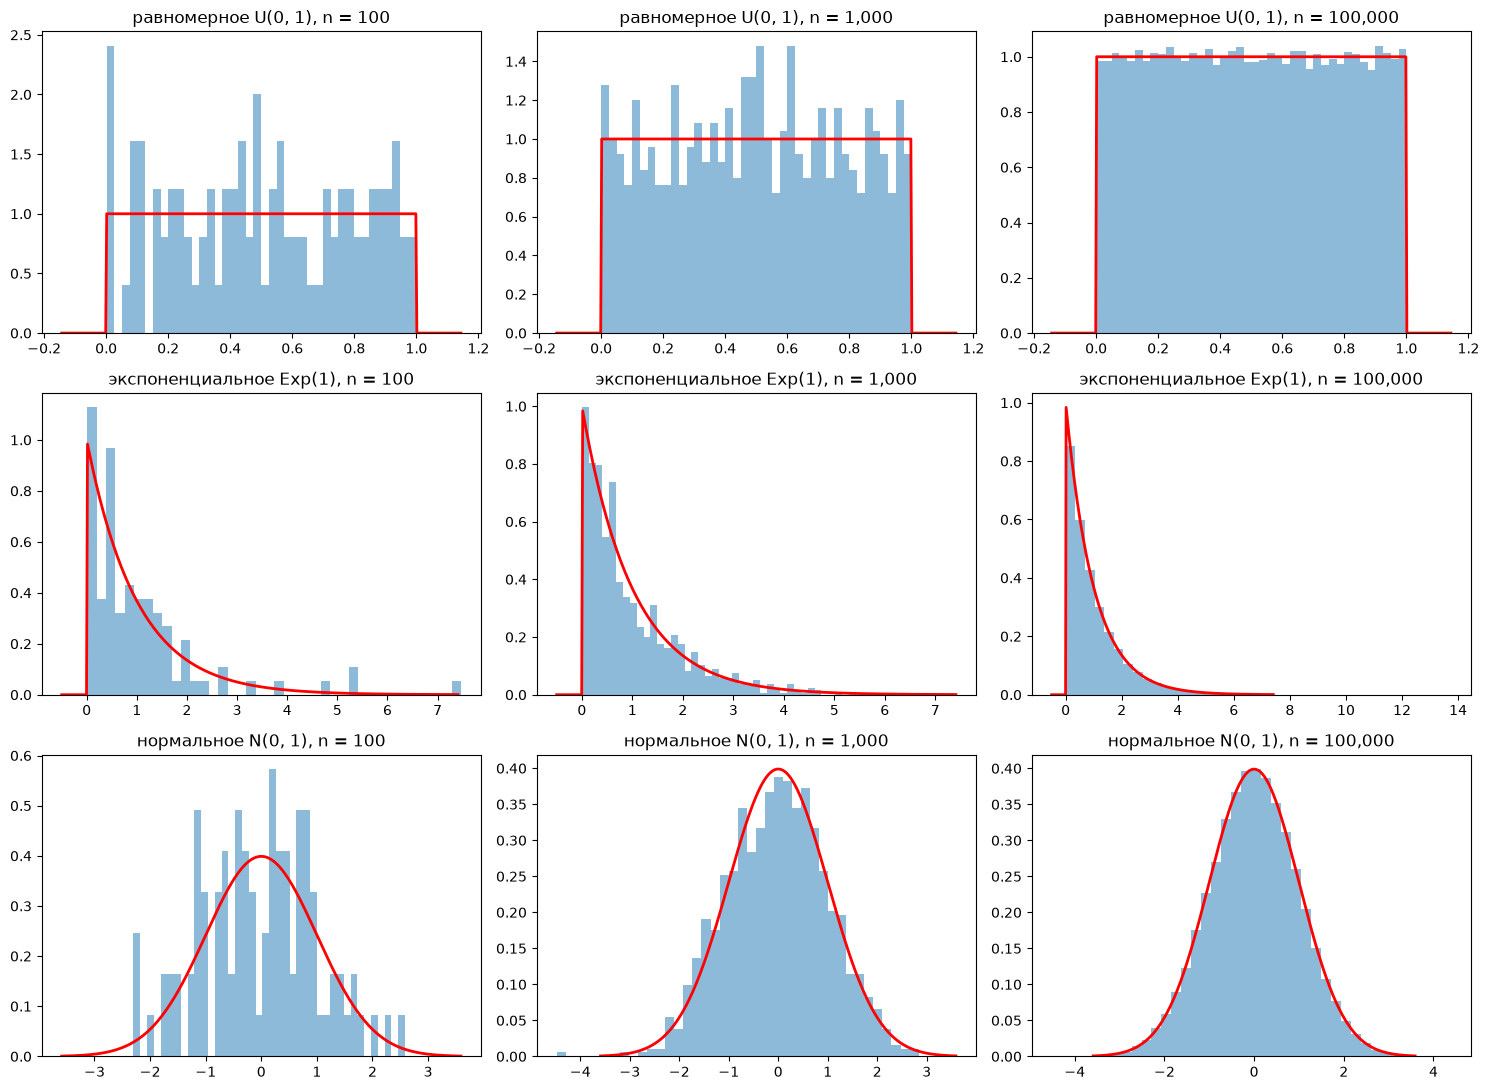

,распределение,n,среднее,теор. среднее,дисперсия,теор. дисперсия
0,"равномерное U(0, 1)",100,0.4997,0.5,0.0865,0.0833
1,"равномерное U(0, 1)",1000,0.4985,0.5,0.0809,0.0833
2,"равномерное U(0, 1)",100000,0.4997,0.5,0.0834,0.0833
3,экспоненциальное Exp(1),100,1.0598,1.0,1.5030,1.0000
4,экспоненциальное Exp(1),1000,0.9811,1.0,0.9088,1.0000
5,экспоненциальное Exp(1),100000,0.9991,1.0,1.0018,1.0000
6,"нормальное N(0, 1)",100,-0.0272,0.0,1.0723,1.0000
7,"нормальное N(0, 1)",1000,-0.0248,0.0,1.0320,1.0000
8,"нормальное N(0, 1)",100000,0.0013,0.0,0.9997,1.0000


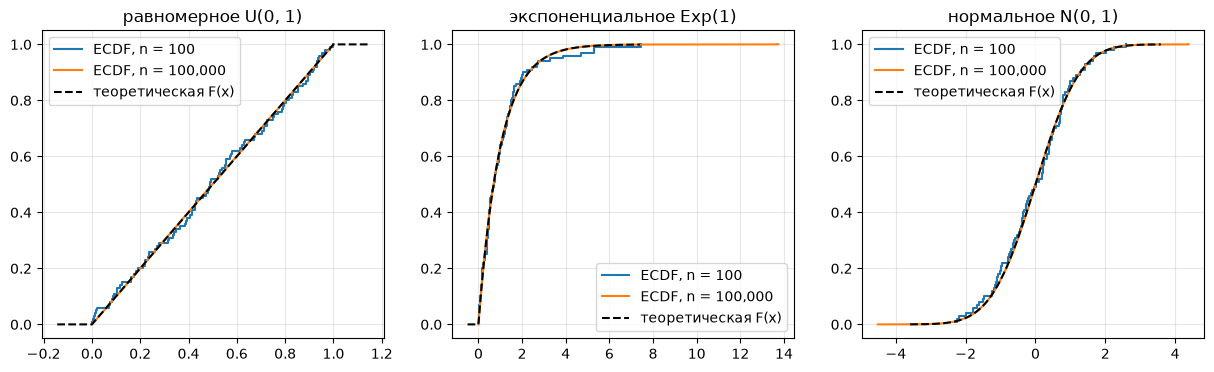

P(X > 2 | X > 1) = 0.3688,  P(X > 1) = 0.3669,  теория e^(−1) = 0.3679
в пределах ±1σ: 0.6828 (теория 0.6827)
в пределах ±2σ: 0.9538 (теория 0.9545)
в пределах ±3σ: 0.9973 (теория 0.9973)


In [9]:
# задание 4
dists = {
    "равномерное U(0, 1)":     stats.uniform(0, 1),
    "экспоненциальное Exp(1)": stats.expon(scale=1),
    "нормальное N(0, 1)":      stats.norm(0, 1),
}
sizes = [100, 1_000, 100_000]
samples = {(name, n): d.rvs(size=n, random_state=rng) for name, d in dists.items() for n in sizes}

def grid_for(d):
    """Сетка x для рисования теоретических кривых."""
    return np.linspace(d.ppf(0.001) - 0.5 * d.std(), d.ppf(0.999) + 0.5 * d.std(), 400)

# 1. Гистограммы + теоретическая плотность
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for row, (name, d) in zip(axes, dists.items()):
    for ax, n in zip(row, sizes):
        ax.hist(samples[(name, n)], bins=40, density=True, alpha=0.5)
        ax.plot(grid_for(d), d.pdf(grid_for(d)), "r", lw=2)
        ax.set_title(f"{name}, n = {n:,}")
plt.tight_layout(); plt.show()

# 2. Выборочные среднее и дисперсия против теории
rows = []
for name, d in dists.items():
    for n in sizes:
        s = samples[(name, n)]
        rows.append({"распределение": name, "n": n,
                     "среднее": s.mean(), "теор. среднее": d.mean(),
                     "дисперсия": s.var(ddof=1), "теор. дисперсия": d.var()})
display(pd.DataFrame(rows).round(4))

# 3. Эмпирическая функция распределения
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, d) in zip(axes, dists.items()):
    for n in (100, 100_000):
        x, y = ecdf(samples[(name, n)])
        ax.step(x, y, where="post", label=f"ECDF, n = {n:,}")
    ax.plot(grid_for(d), d.cdf(grid_for(d)), "k--", label="теоретическая F(x)")
    ax.set_title(name); ax.legend(); ax.grid(alpha=0.3)
plt.show()

# 4. Отсутствие памяти у экспоненциального
x = samples[("экспоненциальное Exp(1)", 100_000)]
print(f"P(X > 2 | X > 1) = {np.mean(x[x > 1] > 2):.4f},  "
      f"P(X > 1) = {np.mean(x > 1):.4f},  теория e^(−1) = {np.exp(-1):.4f}")

# 5. Правило сигм у нормального
z = samples[("нормальное N(0, 1)", 100_000)]
for k, theory in ((1, 0.6827), (2, 0.9545), (3, 0.9973)):
    print(f"в пределах ±{k}σ: {np.mean(np.abs(z) < k):.4f} (теория {theory})")

## 5. Совместные распределения и зависимость

$X \sim N(0, 1)$, $Y = 2X + \varepsilon$, где $\varepsilon \sim N(0, 1)$.

- визуализируй совместное распределение через scatter plot
- вычисли ковариацию и корреляцию
- увеличь дисперсию шума и посмотри, как меняется корреляция
- сравни с независимой величиной $Z \sim N(0, 1)$
- построй пример зависимых величин с корреляцией, близкой к нулю
- объясни, почему отсутствие корреляции не всегда означает независимость

Ковариация:  Cov(X, Y) = E[(X − EX)·(Y − EY)]  — среднее произведение отклонений
Корреляция:  r = Cov(X, Y) / (σX · σY)          — от −1 до 1

Y = 2X + ε,  X ~ N(0, 1),  ε ~ N(0, D(ε)), ε не зависит от X:
Cov(X, Y) = 2·D(X) + Cov(X, ε) = 2·1 + 0 = 2
D(Y) = 4·D(X) + D(ε) = 4 + D(ε)
r = 2 / √(4 + D(ε))
  D(ε) = 1:   r = 2/√5  ≈ 0,894
  D(ε) = 4:   r = 2/√8  ≈ 0,707
  D(ε) = 16:  r = 2/√20 ≈ 0,447

Z независима от X:  Cov = 0, r = 0
W = X² — полностью зависит от X, но
Cov(X, X²) = E[X³] − E[X]·E[X²] = 0 − 0·1 = 0  →  r = 0

Y = 2X + ε, D(ε) = 1  : ковариация =  2.076, корреляция =  0.900 (теория 0.894, NumPy 0.900)
Y = 2X + ε, D(ε) = 4  : ковариация =  2.076, корреляция =  0.719 (теория 0.707, NumPy 0.719)
Y = 2X + ε, D(ε) = 16 : ковариация =  2.093, корреляция =  0.460 (теория 0.447, NumPy 0.460)
Z независимая         : ковариация =  0.013, корреляция =  0.013 (теория 0.000, NumPy 0.013)
W = X², зависимая     : ковариация = -0.071, корреляция = -0.050 (теория 0.000, NumPy -0.050)


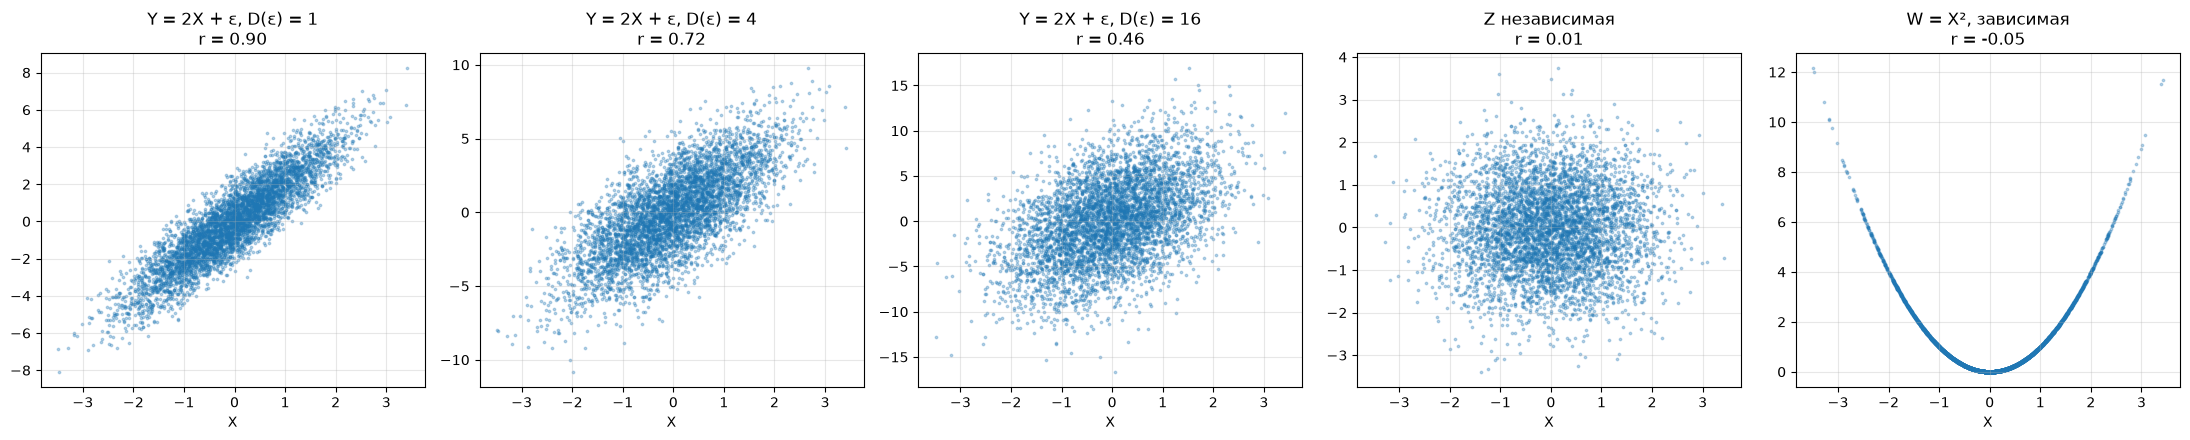

In [11]:
# задание 5
n = 5_000
X = rng.normal(0, 1, n)
Z = rng.normal(0, 1, n)

cases = {}
for noise_var in (1, 4, 16):
    eps = rng.normal(0, np.sqrt(noise_var), n)      # normal принимает σ, поэтому корень из дисперсии
    cases[f"Y = 2X + ε, D(ε) = {noise_var}"] = (2 * X + eps, 2 / np.sqrt(4 + noise_var))
cases["Z независимая"] = (Z, 0.0)
cases["W = X², зависимая"] = (X**2, 0.0)

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (name, (Y, r_theory)) in zip(axes, cases.items()):
    cov, r = cov_corr(X, Y)
    print(f"{name:22}: ковариация = {cov:6.3f}, корреляция = {r:6.3f} "
          f"(теория {r_theory:.3f}, NumPy {np.corrcoef(X, Y)[0, 1]:.3f})")
    ax.scatter(X, Y, s=3, alpha=0.3)
    ax.set_title(f"{name}\nr = {r:.2f}"); ax.set_xlabel("X"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Закон больших чисел и центральная предельная теорема

- сгенерируй броски монеты и построй, как накопленная доля орлов сходится к 0.5
- повтори эксперимент несколько раз и сравни траектории
- выбери ненормальное распределение и многократно вычисли среднее выборок размера 5, 30 и 100
- построй распределения выборочных средних
- сравни их форму, среднее и дисперсию с выводами ЦПТ
- объясни разницу между ЗБЧ и ЦПТ

ЗБЧ: доля орлов после n бросков → 0,5 при n → ∞
Типичное отклонение доли от 0,5 ≈ 0,5/√n:
  10 бросков — ±0,16,   100 — ±0,05,   10 000 — ±0,005

ЦПТ: берём экспоненциальное Exp(1) — кривое, совсем не колокол; E = 1, σ = 1
Среднее выборки из n чисел ≈ N(1, σ/√n) — колокол, хотя исходное кривое:
  n = 5:    σ среднего = 1/√5   ≈ 0,447
  n = 30:   σ среднего = 1/√30  ≈ 0,183
  n = 100:  σ среднего = 1/√100 = 0,1
Чтобы оценка стала в 2 раза точнее, данных нужно в 4 раза больше (из-за √n)

эксперимент 1: после 10 бросков 0.90, после 100 — 0.530, после 10 000 — 0.4955
эксперимент 2: после 10 бросков 0.50, после 100 — 0.520, после 10 000 — 0.5020
эксперимент 3: после 10 бросков 0.40, после 100 — 0.590, после 10 000 — 0.4956
эксперимент 4: после 10 бросков 0.60, после 100 — 0.450, после 10 000 — 0.4955
эксперимент 5: после 10 бросков 0.70, после 100 — 0.630, после 10 000 — 0.5008


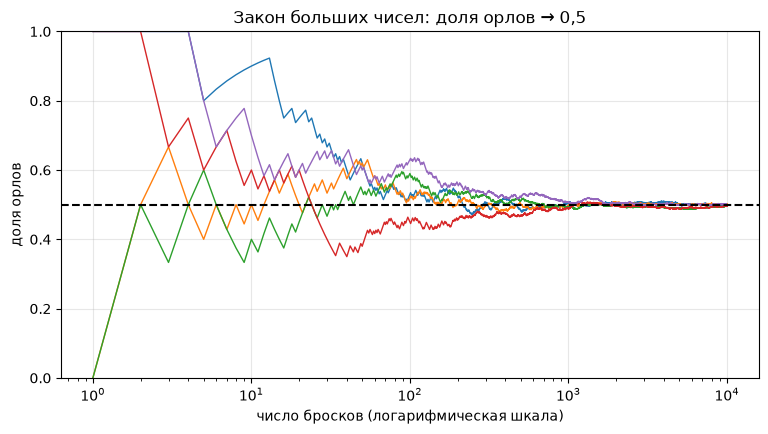

n =   5: среднее средних = 1.003 (ЦПТ: 1), σ средних = 0.448 (ЦПТ: 0.447), асимметрия = 0.88
n =  30: среднее средних = 0.998 (ЦПТ: 1), σ средних = 0.182 (ЦПТ: 0.183), асимметрия = 0.35
n = 100: среднее средних = 1.000 (ЦПТ: 1), σ средних = 0.099 (ЦПТ: 0.100), асимметрия = 0.21


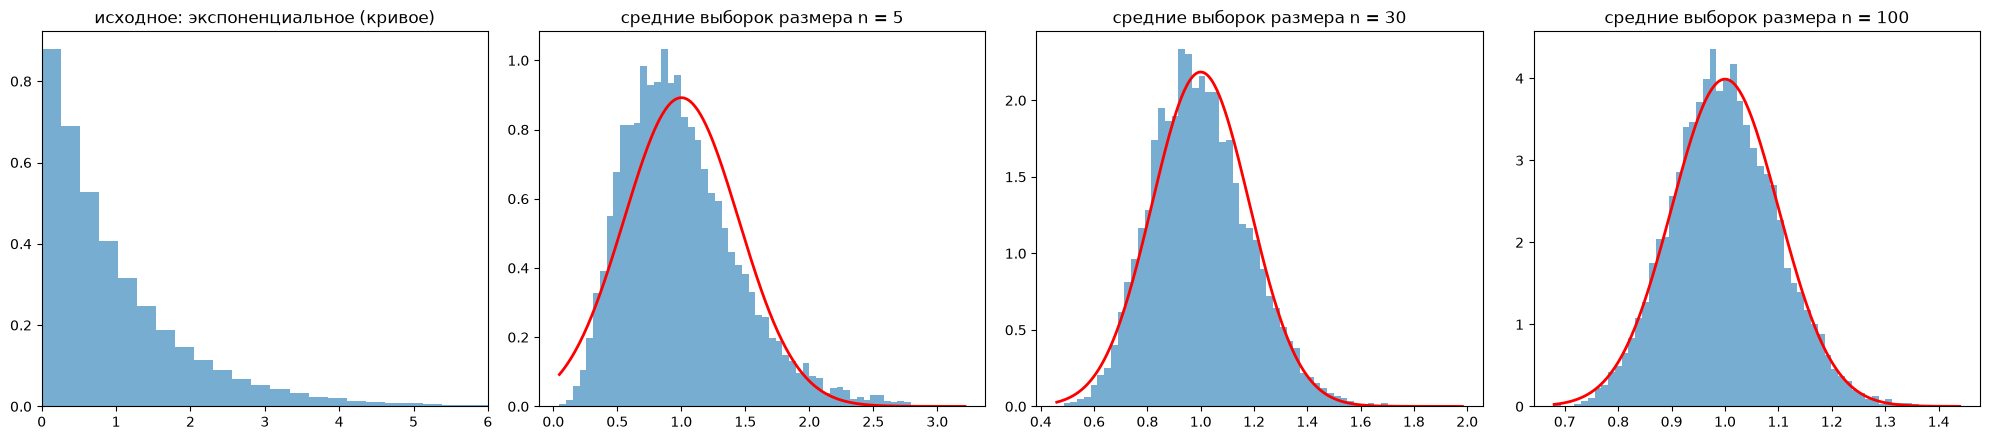

In [12]:
# задание 6
# --- ЗБЧ: 5 экспериментов по 10 000 бросков ---
N = 10_000
plt.figure(figsize=(9, 4.5))
for i in range(5):
    flips = rng.random(N) < 0.5                         # True — орёл
    share = np.cumsum(flips) / np.arange(1, N + 1)      # доля орлов после 1, 2, ..., N бросков
    plt.plot(np.arange(1, N + 1), share, lw=1)
    print(f"эксперимент {i + 1}: после 10 бросков {share[9]:.2f}, "
          f"после 100 — {share[99]:.3f}, после 10 000 — {share[-1]:.4f}")
plt.axhline(0.5, color="black", ls="--")
plt.xscale("log"); plt.ylim(0, 1); plt.grid(alpha=0.3)
plt.xlabel("число бросков (логарифмическая шкала)"); plt.ylabel("доля орлов")
plt.title("Закон больших чисел: доля орлов → 0,5")
plt.show()

# --- ЦПТ: средние выборок из экспоненциального распределения ---
reps = 10_000
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
axes[0].hist(rng.exponential(1, 100_000), bins=60, density=True, alpha=0.6)
axes[0].set_xlim(0, 6); axes[0].set_title("исходное: экспоненциальное (кривое)")

for ax, n in zip(axes[1:], (5, 30, 100)):
    means = rng.exponential(1, (reps, n)).mean(axis=1)  # 10 000 выборок по n чисел → 10 000 средних
    se = 1 / np.sqrt(n)                                  # ЦПТ: σ средних = σ / √n
    grid = np.linspace(means.min(), means.max(), 300)
    ax.hist(means, bins=60, density=True, alpha=0.6)
    ax.plot(grid, stats.norm.pdf(grid, 1, se), "r", lw=2)   # колокол, который предсказывает ЦПТ
    ax.set_title(f"средние выборок размера n = {n}")
    print(f"n = {n:3}: среднее средних = {means.mean():.3f} (ЦПТ: 1), "
          f"σ средних = {means.std():.3f} (ЦПТ: {se:.3f}), асимметрия = {stats.skew(means):.2f}")
plt.tight_layout(); plt.show()

## 7. Цепь Маркова

Модель погоды: солнечно, облачно, дождь; матрица переходов задаётся самостоятельно.

- проверь, что сумма вероятностей в каждой строке равна 1
- вычисли распределение состояний через 1, 5, 20 и 100 шагов
- смоделируй одну траекторию длиной 1 000 дней
- сравни доли состояний в симуляции с предельным распределением
- измени одну вероятность перехода и исследуй, как меняется долгосрочное поведение

Состояния: 0 — солнечно, 1 — облачно, 2 — дождь
         солн  обл  дождь
P = солн [0.7  0.2  0.1]    сумма = 1
    обл  [0.3  0.4  0.3]    сумма = 1
    дождь[0.2  0.3  0.5]    сумма = 1

Старт: сегодня солнечно, p0 = [1, 0, 0]
Шаг 1: p1 = p0·P = первая строка = [0.7, 0.2, 0.1]
Шаг 2: p2 = p1·P = 0.7·[0.7, 0.2, 0.1] + 0.2·[0.3, 0.4, 0.3] + 0.1·[0.2, 0.3, 0.5]
          = [0.57, 0.25, 0.18]      (сумма = 1 ✓)
Через k шагов: pk = p0·P^k  (P^k = P·P·…·P, k раз)

Стационарное π: π·P = π, т.е. собственный вектор Pᵀ с λ = 1
π = [21/46, 13/46, 12/46] ≈ [0.457, 0.283, 0.261]
Проверка 1-го числа: 0.457·0.7 + 0.283·0.3 + 0.261·0.2 = 0.320 + 0.085 + 0.052 ≈ 0.457 ✓

суммы строк: [1. 1. 1.] → все равны 1: True
                       солнечно  облачно   дождь
1 шаг                    0.7000   0.2000  0.1000
5 шаг                    0.4685   0.2794  0.2521
20 шаг                   0.4565   0.2826  0.2609
100 шаг                  0.4565   0.2826  0.2609
старт «дождь», 20 шаг    0.4565   0.2826  0.2609
стационарное π           0.4565   0.2826  0.2609 

          симуляция      π  симуляция (новая P)  π (новая P)
солнечно      0.469  0.457                0.446        0.441
облачно       0.277  0.283                0.206        0.206
дождь         0.254  0.261                0.348        0.353


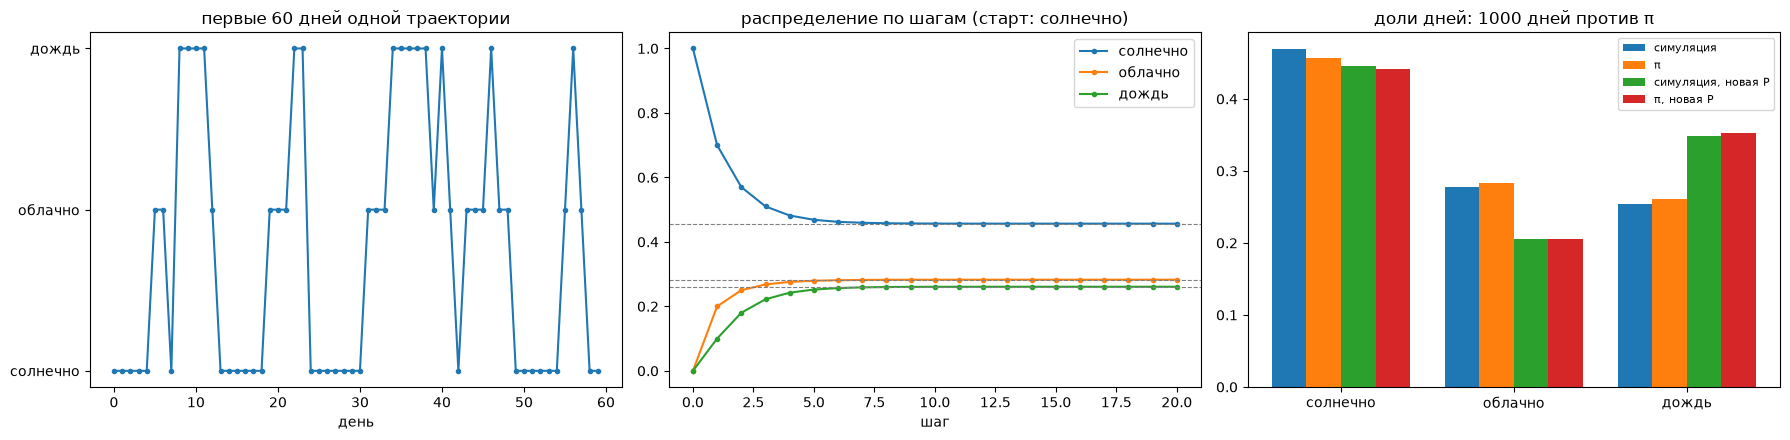

In [18]:
# задание 7


STATES = ["солнечно", "облачно", "дождь"]
P = np.array([[0.7, 0.2, 0.1],     # из «солнечно» в: солнечно, облачно, дождь
              [0.3, 0.4, 0.3],     # из «облачно»
              [0.2, 0.3, 0.5]])    # из «дождь»
print("суммы строк:", P.sum(axis=1), "→ все равны 1:", np.allclose(P.sum(axis=1), 1))

# распределение через 1, 5, 20, 100 шагов
sunny, rain = np.array([1, 0, 0]), np.array([0, 0, 1])
pi = stationary(P)
table = pd.DataFrame({f"{k} шаг": dist_after(sunny, P, k) for k in (1, 5, 20, 100)}, index=STATES).T
table.loc["старт «дождь», 20 шаг"] = dist_after(rain, P, 20)    # старт не важен
table.loc["стационарное π"] = pi
print(table.round(4), "\n")

# траектория 1000 дней
path = simulate_chain(P, start=0, n=1000)
sim = np.bincount(path, minlength=3) / len(path)     # доля дней в каждом состоянии

# меняем одну вероятность: дождь→дождь 0.5 → 0.7 (0.2 забираем у дождь→облачно, чтобы сумма осталась 1)
P2 = P.copy()
P2[2] = [0.2, 0.1, 0.7]
pi2 = stationary(P2)
sim2 = np.bincount(simulate_chain(P2, 0, 1000), minlength=3) / 1000
print(pd.DataFrame({"симуляция": sim, "π": pi,
                    "симуляция (новая P)": sim2, "π (новая P)": pi2}, index=STATES).round(3))

# графики
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(path[:60], "o-", ms=3)
axes[0].set_yticks([0, 1, 2], STATES)
axes[0].set_title("первые 60 дней одной траектории"); axes[0].set_xlabel("день")

steps = np.arange(21)
probs = np.array([dist_after(sunny, P, k) for k in steps])
for j, s in enumerate(STATES):
    axes[1].plot(steps, probs[:, j], "o-", ms=3, label=s)
    axes[1].axhline(pi[j], ls="--", color="gray", lw=0.8)       # пунктир — π
axes[1].set_title("распределение по шагам (старт: солнечно)"); axes[1].set_xlabel("шаг"); axes[1].legend()

x, w = np.arange(3), 0.2
axes[2].bar(x - 1.5 * w, sim, w, label="симуляция")
axes[2].bar(x - 0.5 * w, pi, w, label="π")
axes[2].bar(x + 0.5 * w, sim2, w, label="симуляция, новая P")
axes[2].bar(x + 1.5 * w, pi2, w, label="π, новая P")
axes[2].set_xticks(x, STATES); axes[2].set_title("доли дней: 1000 дней против π"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Где это в машинном обучении

_Примеры: условная вероятность, математическое ожидание, нормальное распределение и предельные теоремы в ML._

...

Условная вероятность и Байес (задание 2): при редкой болезни (1%) положительный тест означает болезнь только в 16% случаев. Так же с детектором мошенничества в финтехе: модель с «95% точности» на редком классе выдаёт в основном ложные тревоги. В ML это называют precision, и она сильно зависит от того, насколько класс редкий.
Мат. ожидание (задание 3): функция потерь — это средняя ошибка модели по данным, и обучение её минимизирует. Число правильных ответов модели из n тестовых примеров распределено по биномиальному закону.
Нормальное распределение и правило 3σ (задание 4): признаки перед обучением стандартизируют: z = (x − μ)/σ. Значение дальше 3σ от среднего подозрительно: так ловят выбросы и аномалии в метриках, например всплески latency в мониторинге.
Корреляция (задание 5): по ней отбирают признаки. Но r ≈ 0 не значит «связи нет»: на параболе r = 0.013, а зависимость полная, и линейная модель её не увидит.
ЗБЧ и ЦПТ (задание 6): градиент по мини-батчу — это среднее, и оно приближается к настоящему градиенту, а шум уменьшается как 1/√batch. Точность на тест-наборе тоже среднее: её погрешность ±1.96·√(p(1−p)/n).
Цепь Маркова (задание 7): языковая модель генерирует текст по шагам, выбирая следующий токен по вероятностям. В обучении с подкреплением агент тоже переходит между состояниями.

## Перед сдачей

- [ ] `Restart & Run All` проходит без ошибок
- [ ] у каждого задания есть: теория → симуляция → график → вывод
- [ ] выводы написаны своими словами